# Movements parameters extraction

## Imports

In [10]:
import sys
import os

CUT_STRING = "src/master_thesis_data_analysis/data"

sys.path.append(os.path.join(os.getcwd().split(CUT_STRING)[0], CUT_STRING))
SRC_PATH = os.path.join(os.getcwd().split(CUT_STRING)[0], 'src')
from framework import *

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from scipy.signal import find_peaks
from scipy.integrate import cumulative_trapezoid


## Literals

In [11]:
# ------------------------------------------------------------------ Input files
# CSV_FILE = Path("/home/ddacunto/Desktop/ros2_ws/recording_csv/NOEMI_BIANCAMANO/CHECK_XY/recording_1.csv")

CSV_FILE = Path(f"{SRC_PATH}/../recording_csv/ROSANNA_COCCARO/LETTER_N/recording_18.csv")
YAML_PATHS_FILE = Path(f"{SRC_PATH}/unisa_acg_ros2/haptics/haptic_interaction_teach_and_record_demo/config/paths.yaml")

TASK = CSV_FILE.parent.name

POSITION_COLUMNS = ["position_x", "position_y", "position_z"]
VELOCITY_COLUMNS = ["twist_linear_x", "twist_linear_y", "twist_linear_z"]

# ------------------------------------------------- Low-pass Chebyshev II filter
FILTER_ORDER = 11
FILTER_CUTOFF_HZ = 16
FILTER_STOPBAND_DB = 80
TARGET_FREQUENCY = 500  # Hz
# ------------------------------------------------------ Low-speed edge trimming
SPEED_THRESHOLD = 0.035  # m/s (or relative, e.g. 0.05 * speed.max())
EDGE_MARGIN_S = 0.03     # safety margin kept around the above-threshold part

# ------------------------------------------ Waypoints: normalized -> device frame
SWAP_YZ_WAYPOINTS = False
WS_MIN = np.array([-0.082, -0.065, -0.085])
WS_MAX = np.array([0.082, 0.065, 0.085])

# ---------------------------------------------------------------- Lognormal fit
FIT_OPTIONS = dict(
    sigma_bounds=(0.05, 1.5),  # allowed range for the lognormal sigma
    max_lead=1.0,              # t0 may precede the window start by max_lead * window duration
)
STEPS_TO_PLOT = None  # None = plot every step, or e.g. [0, 1]

# --------------------------------------------------------------- Joint refinement
REFINE_OPTIONS = dict(
    t0_shift_frac=0.5,  # t0 may move by +/- this fraction of the stroke window duration
    mu_shift=1.0,       # mu may move by +/- this amount
    reg_weight=0.0,     # > 0 pulls the parameters toward the sequential solution
)

# ------------------------------------------------------------------------ Lengths
LOCK_D_TO_GEOMETRY = True  # D of each stroke = measured path length between its two speed minima

# ------------------------------------------------------- Geometric reconstruction
ANGLE_STEP_RAD = np.deg2rad(1.0)  # angular sensitivity of the exit/entry angles
ANGLE_LIMITS = (-np.pi, np.pi)
PLOT_RECONSTRUCTIONS = True

# ------------------------------------------ Model speed trimmed by travelled distance
MODEL_END_TIME_S = 10.0  # end of the time grid on which the model speed is evaluated
TRIM_START_M = 0.00005     # .05 mm
TRIM_END_M = 0.00005       # .05 mm

## Tasks

In [12]:
def load_waypoints(yaml_file, task):
    with open(yaml_file, "r") as f:
        paths = yaml.safe_load(f)["paths"]
    for path in paths:
        if path["name"] == task:
            return path["waypoints"]
    raise KeyError(f"Task '{task}' not found in {yaml_file}")


def waypoints_to_array(waypoints, swap_yz=False, ws_min=None, ws_max=None):
    """Convert the list of {'x','y','z'} dicts (normalized) into an Nx3 array in device coordinates."""
    arr = np.array([[w["x"], w["y"], w["z"]] for w in waypoints], dtype=float)
    if swap_yz:
        arr[:, [1, 2]] = arr[:, [2, 1]]
    if ws_min is not None and ws_max is not None:
        ws_min = np.asarray(ws_min, dtype=float)
        ws_max = np.asarray(ws_max, dtype=float)
        arr = ws_min + arr * (ws_max - ws_min)
    return arr


WAYPOINTS = load_waypoints(YAML_PATHS_FILE, TASK)
waypoints_xyz = waypoints_to_array(WAYPOINTS, SWAP_YZ_WAYPOINTS, WS_MIN, WS_MAX)
csv_data = pd.read_csv(CSV_FILE)
csv_data['timestamp'] = csv_data['timestamp'] - csv_data['timestamp'].iloc[0]  # normalize timestamps to start at 0
csv_data['timestamp'] = csv_data['timestamp'] / 1e9  # convert from nanoseconds to seconds
print(WAYPOINTS)

[{'x': 0.1, 'y': 0.1, 'z': 0.5}, {'x': 0.1, 'y': 0.9, 'z': 0.5}, {'x': 0.9, 'y': 0.1, 'z': 0.5}, {'x': 0.9, 'y': 0.9, 'z': 0.5}]


## Pipeline

### Load the recording data

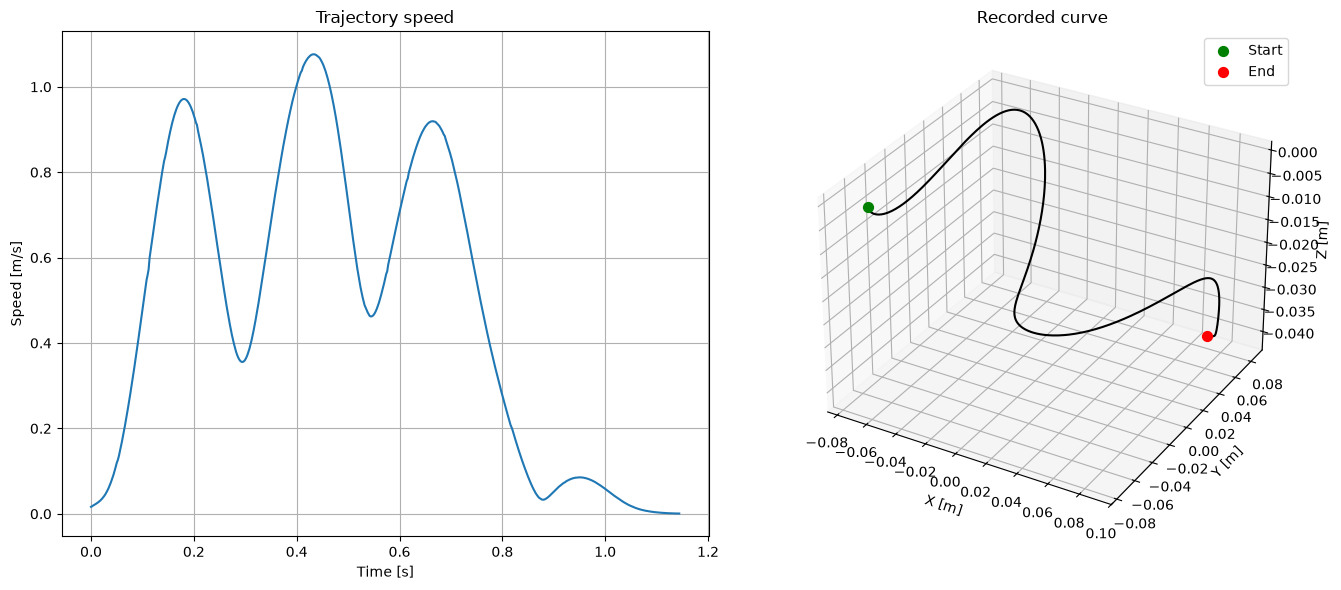

In [13]:
recording = Recording(
  trajectory=Trajectory(
    vx  = csv_data[VELOCITY_COLUMNS[0]].to_numpy(),
    vy  = csv_data[VELOCITY_COLUMNS[1]].to_numpy(),
    vz  = csv_data[VELOCITY_COLUMNS[2]].to_numpy(),
  ),
  curve=Curve(
    x   = csv_data[POSITION_COLUMNS[0]].to_numpy(),
    y   = csv_data[POSITION_COLUMNS[1]].to_numpy(),
    z   = csv_data[POSITION_COLUMNS[2]].to_numpy(),
  ),
    t   = csv_data['timestamp'].to_numpy()
)
filter = Chebyshev(order=FILTER_ORDER, cutoff=FILTER_CUTOFF_HZ, stopband_attenuation=FILTER_STOPBAND_DB)
resampler = Resample(target_fs=TARGET_FREQUENCY)
recording.trajectory = filter.apply(recording.trajectory) # type: ignore
recording.curve = filter.apply(recording.curve) # type: ignore
recording.trajectory = resampler.apply(recording.trajectory) # type: ignore
recording.curve = resampler.apply(recording.curve) # type: ignore

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1)
ax1.plot(
  recording.trajectory.t,
  recording.trajectory.speed,
  color="tab:blue",
  linewidth=1.5,
)
ax1.set_xlabel("Time [s]")
ax1.set_ylabel("Speed [m/s]")
ax1.set_title("Trajectory speed")
ax1.grid(True)

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
curve_points = np.asarray(recording.curve.points)
ax2.plot(
  curve_points[:, 0],
  curve_points[:, 1],
  curve_points[:, 2],
  color="black",
  linewidth=1.5,
)
ax2.scatter(*curve_points[0], color="green", s=50, label="Start")
ax2.scatter(*curve_points[-1], color="red", s=50, label="End")
ax2.set_xlabel("X [m]")
ax2.set_ylabel("Y [m]")
ax2.set_zlabel("Z [m]")
ax2.set_title("Recorded curve")
ax2.legend()

plt.tight_layout()
plt.show()

### Detect Speed Minima and Maxima

In [14]:
def find_minima_maxima(speed:np.ndarray, samples_distance:float|None=None, prominence:float|None=None) -> tuple[list[int], list[int]]:
    """Find the indices of the speed minima and maxima in the given speed array."""
    # Find local maxima
    maxima_indices, _ = find_peaks(speed, distance=samples_distance, prominence=prominence)
    # Find local minima by inverting the speed
    minima_indices, _ = find_peaks(-speed, distance=samples_distance, prominence=prominence)
    try:
        if minima_indices[0] > maxima_indices[0]:
            if speed[0] < speed[maxima_indices[0]]:
                minima_indices = np.r_[0, minima_indices]
            else:
                if speed[0] > speed[minima_indices[0]]:
                    maxima_indices = np.r_[0, maxima_indices]

        if minima_indices[-1] < maxima_indices[-1]:
            if speed[-1] < speed[maxima_indices[-1]]:
                minima_indices = np.r_[minima_indices, speed.size - 1]
            else:
                if speed[-1] > speed[minima_indices[-1]]:
                    maxima_indices = np.r_[maxima_indices, speed.size - 1]
    except IndexError:
        if len(minima_indices) == 0 and len(maxima_indices) == 1:
            minima_indices = np.array([0, speed.size - 1])
    return minima_indices, maxima_indices

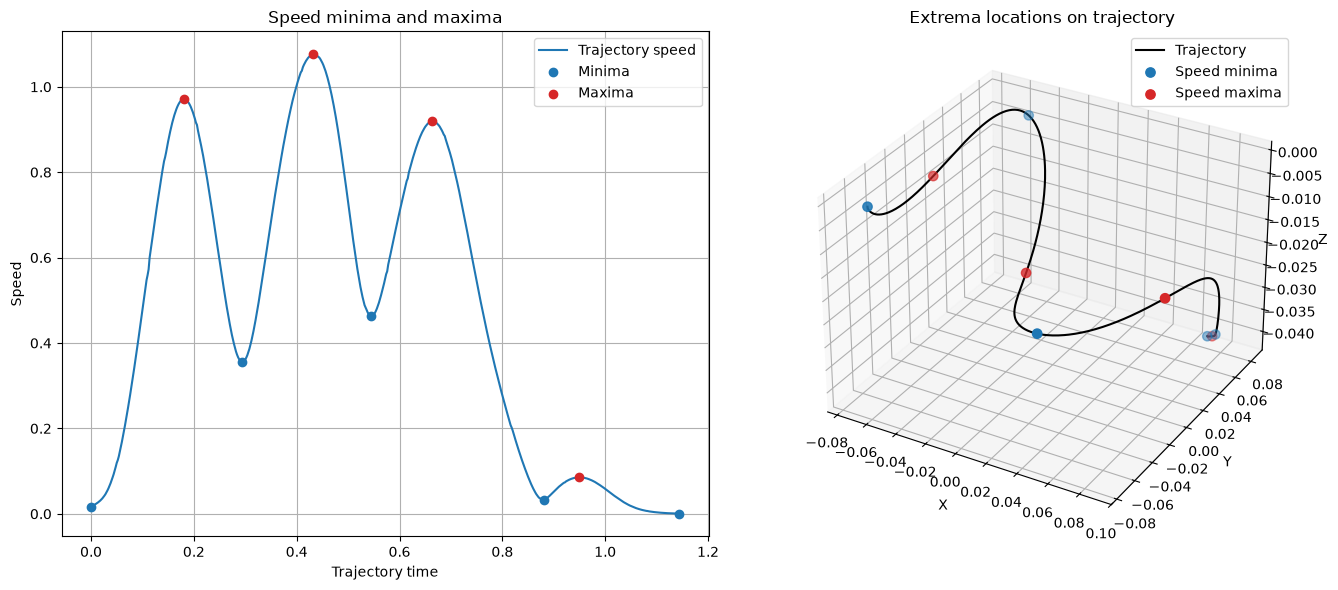

Detected 5 speed minima and 4 speed maxima.
Speed minima indices: [  0 147 272 440 572]
Speed maxima indices: [ 90 216 332 475]
Speed profile length: 573


In [15]:
speed = recording.trajectory.speed
speed_time = recording.trajectory.t

# Detect significant local extrema.
peak_distance = max(1, speed.size // 100)
prominence = 0.008
TIME_DISTANCE = .1 #s
PROMINENCE = .005 #m/s
frequency = np.median(np.diff(recording.trajectory.t))  # Estimate the sampling frequency from the trajectory timestamps
minima_idx, maxima_idx = find_minima_maxima(speed, samples_distance=TIME_DISTANCE / frequency, prominence = PROMINENCE)


# Interpolate trajectory positions onto the speed samples.
speed_positions = np.column_stack([
  np.interp(speed_time, recording.trajectory.t, recording.curve.points[:, axis])
  for axis in range(3)
])

fig = plt.figure(figsize=(14, 6))

# Speed profile with extrema.
ax1 = fig.add_subplot(1, 2, 1)
ax1.plot(speed_time, speed, label="Trajectory speed")
ax1.scatter(speed_time[minima_idx], speed[minima_idx],
      color="tab:blue", label="Minima", zorder=3)
ax1.scatter(speed_time[maxima_idx], speed[maxima_idx],
      color="tab:red", label="Maxima", zorder=3)
ax1.set_xlabel("Trajectory time")
ax1.set_ylabel("Speed")
ax1.set_title("Speed minima and maxima")
ax1.grid(True)
ax1.legend()

# 3D trajectory with extrema.
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot(
  speed_positions[:, 0],
  speed_positions[:, 1],
  speed_positions[:, 2],
  color="black",
  label="Trajectory",
)
ax2.scatter(
  speed_positions[minima_idx, 0],
  speed_positions[minima_idx, 1],
  speed_positions[minima_idx, 2],
  color="tab:blue",
  s=45,
  label="Speed minima",
)
ax2.scatter(
  speed_positions[maxima_idx, 0],
  speed_positions[maxima_idx, 1],
  speed_positions[maxima_idx, 2],
  color="tab:red",
  s=45,
  label="Speed maxima",
)

ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.set_zlabel("Z")
ax2.set_title("Extrema locations on trajectory")
ax2.legend()

plt.tight_layout()
plt.show()
print(f"Detected {len(minima_idx)} speed minima and {len(maxima_idx)} speed maxima.")
print(f"Speed minima indices: {minima_idx}")
print(f"Speed maxima indices: {maxima_idx}")
print(f"Speed profile length: {len(speed)}")

### Extract trajectory parameters

In [16]:
ls = LeastSquares(
  boundaries=minima_idx,
  lock_D=LOCK_D_TO_GEOMETRY,
  refine=False
)

reconstructed_strokes = ls.approximate(recording)

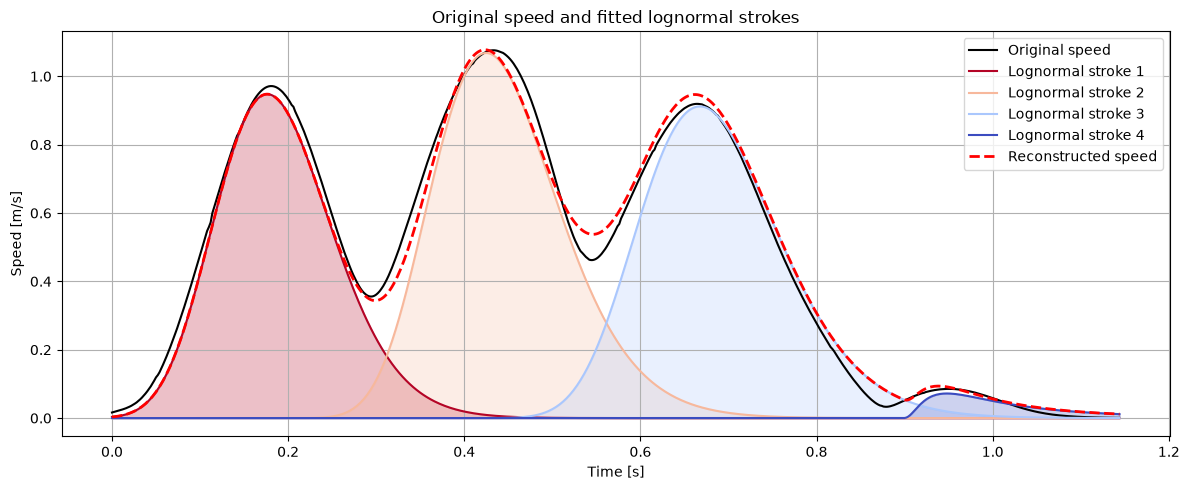

SNR: 24.46 dB


In [17]:
# Inspect this once if the attribute name is unknown:
# print(vars(reconstructed_strokes))

stroke_list = reconstructed_strokes.strokes  # change to the actual collection attribute if needed
reconstructed_stroke_list = reconstructed_strokes.strokes

t = recording.t
reconstructed_speed = np.zeros_like(t, dtype=float)
colors = plt.cm.coolwarm_r(np.linspace(0, 1, len(stroke_list)))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
  t,
  recording.trajectory.speed,
  color="black",
  linewidth=1.5,
  label="Original speed",
)

for i, (stroke, color) in enumerate(zip(stroke_list, colors), start=1):
  t0 = float(stroke.to)
  mu = float(stroke.mu)
  sigma = float(stroke.sigma)
  D = abs(float(stroke.D))

  tau = t - t0
  valid = tau > 0
  density = np.zeros_like(t, dtype=float)

  density[valid] = (
    D
    / (sigma * np.sqrt(2 * np.pi) * tau[valid])
    * np.exp(-((np.log(tau[valid]) - mu) ** 2) / (2 * sigma**2))
  )

  reconstructed_speed += density

  ax.plot(t, density, color=color, linewidth=1.5,
      label=f"Lognormal stroke {i}")
  ax.fill_between(t, density, color=color, alpha=0.25)

ax.plot(
  t,
  reconstructed_speed,
  "--",
  color="red",
  linewidth=2,
  label="Reconstructed speed",
)

ax.set_xlabel("Time [s]")
ax.set_ylabel("Speed [m/s]")
ax.set_title("Original speed and fitted lognormal strokes")
ax.grid(True)
ax.legend()
plt.tight_layout()
plt.show()

print(f"SNR: {SNR(recording.trajectory.speed, reconstructed_speed):.2f} dB")


In [18]:
def filter_strokes_by_D(strokes:StrokeSequence, threshold:float) -> tuple[StrokeSequence, Stroke|None]:
    Ds = []
    for stroke in strokes:
        Ds.append(stroke.D)

    filtered_strokes = []
    for stroke in strokes:
        if stroke.D > threshold:
            filtered_strokes.append(stroke)

    corrective_last_stroke = None
    last_filtered_index = strokes.strokes.index(filtered_strokes[-1])
    if len(strokes) > last_filtered_index + 1:
        corrective_last_stroke = strokes.get(last_filtered_index + 1)

    return StrokeSequence(filtered_strokes), corrective_last_stroke

filtered_strokes, last_stroke = filter_strokes_by_D(reconstructed_strokes, 0.075)
#start_time = filtered_strokes.strokes[0].to
#for stroke in filtered_strokes.strokes:
#    stroke.to -= start_time
print([f"stroke to {stroke.to}" for stroke in filtered_strokes])



['stroke to -0.2939999999999999', 'stroke to 0.043999999999999935', 'stroke to 0.21656422913624124']


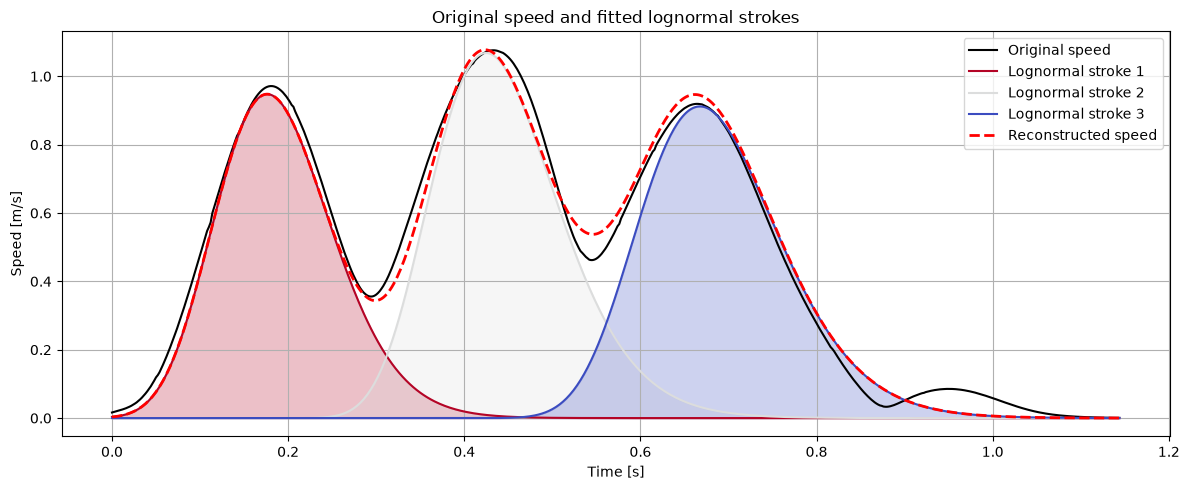

SNR: 23.52 dB
Filtered stroke parameters:
Stroke 1: to=-0.294000, mu=-0.735113, sigma=0.139376, D=0.157229
Stroke 2: to=0.044000, mu=-0.930532, sigma=0.186725, D=0.193773
Stroke 3: to=0.216564, mu=-0.765982, sigma=0.174255, D=0.182381


In [19]:
# Inspect this once if the attribute name is unknown:
# print(vars(strokes))

stroke_list = filtered_strokes.strokes  # change to the actual collection attribute if needed

t = recording.t
reconstructed_speed = np.zeros_like(t, dtype=float)
colors = plt.cm.coolwarm_r(np.linspace(0, 1, len(stroke_list)))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
  t,
  recording.trajectory.speed,
  color="black",
  linewidth=1.5,
  label="Original speed",
)

for i, (stroke, color) in enumerate(zip(stroke_list, colors), start=1):
  t0 = float(stroke.to)
  mu = float(stroke.mu)
  sigma = float(stroke.sigma)
  D = abs(float(stroke.D))

  tau = t - t0
  valid = tau > 0
  density = np.zeros_like(t, dtype=float)

  density[valid] = (
    D
    / (sigma * np.sqrt(2 * np.pi) * tau[valid])
    * np.exp(-((np.log(tau[valid]) - mu) ** 2) / (2 * sigma**2))
  )

  reconstructed_speed += density

  ax.plot(t, density, color=color, linewidth=1.5,
      label=f"Lognormal stroke {i}")
  ax.fill_between(t, density, color=color, alpha=0.25)

ax.plot(
  t,
  reconstructed_speed,
  "--",
  color="red",
  linewidth=2,
  label="Reconstructed speed",
)

ax.set_xlabel("Time [s]")
ax.set_ylabel("Speed [m/s]")
ax.set_title("Original speed and fitted lognormal strokes")
ax.grid(True)
ax.legend()
plt.tight_layout()
plt.show()

print(f"SNR: {SNR(recording.trajectory.speed, reconstructed_speed):.2f} dB")
print("Filtered stroke parameters:")
for i, stroke in enumerate(stroke_list, start=1):
  print(
    f"Stroke {i}: "
    f"to={float(stroke.to):.6f}, "
    f"mu={float(stroke.mu):.6f}, "
    f"sigma={float(stroke.sigma):.6f}, "
    f"D={float(stroke.D):.6f}"
  )

### Extract curve parameters

A Bézier spline is a sequence of curves. Being $P_0',P_1',P_2',P_3'$ the points of the next curve $B'(\nu)$, $C^0$ continuity imposes
$$P_0'=P_3$$


A cubic Bézier curve is defined by 4 points $P_0,P_1,P_2,P_3$:
$$B(\nu)=(1-\nu)^3P_0+3(1-\nu)^2\nu\,P_1+3(1-\nu)\nu^2P_2+\nu^3P_3,\qquad \nu\in[0,1]$$
Its derivative with respect to $\nu$ is:
$$\frac{dB}{d\nu}=3(1-\nu)^2(P_1-P_0)+6(1-\nu)\nu(P_2-P_1)+3\nu^2(P_3-P_2)$$

$C^0$ continuity ensures that the curve is linked at the joint: $$B(1)=P_3=B'(0)=P_0'$$
$C^1$ continuity imposes that the derivative at the joint is the same: $$\frac{dB'}{d\nu}(0)=3(P_1'-P_0')=\frac{dB}{d\nu}(1)=3(P_3-P_2)\Rightarrow P_1'=2P_3-P_2$$
In other words, $P_3$ is the mid point of the segment $P_2P_1'$.

So, the two points $P_1$ and $P_2$ are computed as: $$P_1 = P_0 + \lambda_s\cdot c \cdot u_s,\qquad P_2 = P_3 - \lambda_e\cdot c \cdot u_e$$

Let $c=\|P_3-P_0\|$ be the chord of the curve. For the curve $k$ the network generates:
- the reached point as a difference $\Delta P$ with respect to $P_0$: $P_3=P_0+\Delta P$, so $c=\|\Delta P\|$
- the direction of entry in $P_3$: $\mathbf{u_e}$
- a parameter proportional to the second handle length: $\lambda_e$

The point $P_0$ and the exit direction $\mathbf{u_s}$ and parameter $\lambda_s$ are inherited from the previous curve, so that $C^0$ and $C^1$ hold; only for the first curve are $\mathbf{u_s}$ and $\lambda_s$ generated too.
$$P_1=P_0+\lambda_s\,c\,\mathbf{u_s},\qquad P_2=P_3-\lambda_e\,c\,\mathbf{u_e}$$
With the same parameter interval for consecutive curves, $P_1'=2P_3-P_2$ gives, for the next curve (chord $c'$),
$$\mathbf{u_s'}=\mathbf{u_e},\qquad \lambda_s'=\lambda_e\,\frac{c}{c'}$$
The length $D=\int_0^1\left\|\frac{dB}{d\nu}\right\|d\nu$ is not generated: it is computed from the curve.

Start time: 0.0, End time: 0.88


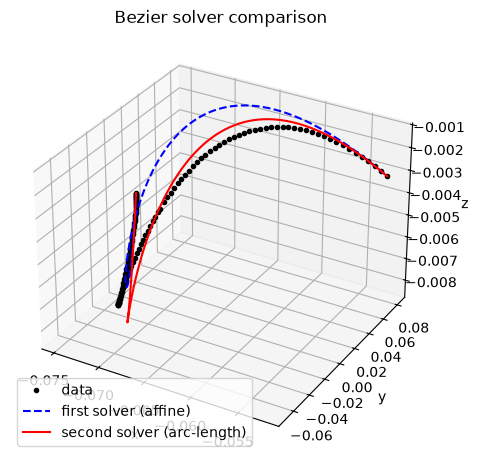

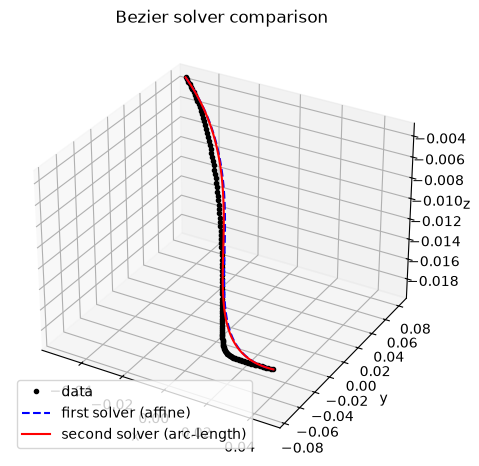

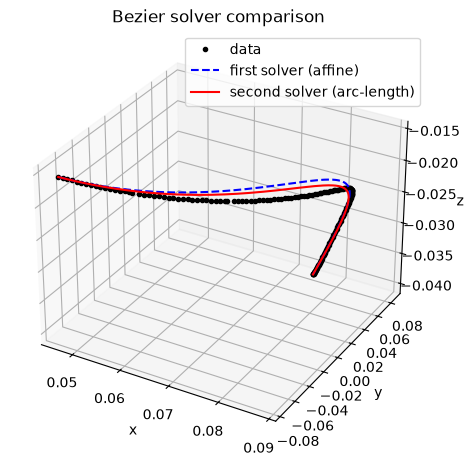

In [20]:
minima_idx_strokes = []

USE_FILTERED = True

if USE_FILTERED:
  for stroke in filtered_strokes:
    stroke_index = reconstructed_strokes.strokes.index(stroke)
    minima_idx_strokes.append(minima_idx[stroke_index])
    minima_idx_strokes.append(minima_idx[stroke_index + 1])  # Include the next minimum for the last stroke

  minima_idx_strokes = sorted(set(minima_idx_strokes))  # Remove duplicates and sort
  generating_strokes = list(filtered_strokes.strokes)
else:
  minima_idx_strokes = list(minima_idx)  # Use all minima indices if not filtering
  generating_strokes = list(reconstructed_strokes.strokes)

if len(generating_strokes) != len(minima_idx_strokes) - 1:
  raise ValueError(
    f"{len(generating_strokes)} strokes for {len(minima_idx_strokes) - 1} windows: the kept strokes must be "
    "contiguous, so that each window between two speed minima belongs to exactly one stroke.")

# D of each stroke, shared by its lognormal speed profile and by the length of its Bezier segment
Ds = [abs(float(stroke.D)) for stroke in generating_strokes]

start_time = recording.t[minima_idx_strokes[0]]
end_time = recording.t[minima_idx_strokes[-1]]
print(f"Start time: {start_time}, End time: {end_time}")

# Geometry: one Bezier per window between consecutive speed minima, with arc length Ds[i]
approx = BezierOptimization()
approx.set_problem(minima_idx=minima_idx_strokes, Ds=Ds, lambda_min=1e-3,
                   direction_distance=2.5e-3, lambda_max=None, plot_comparison=True)
curve_params, _ = approx.approximate(recording.curve)

# First point of each Bezier segment: segment i starts at the speed minimum minima_idx_strokes[i]
segment_start_points = np.asarray(recording.curve.points)[np.asarray(minima_idx_strokes[:-1], dtype=int)]


## New extraction
The Bézier curve fixed parameters are:
- $P_0$
- $P_3$
- $\mathbf{u_s}$ with 1mm difference from $P_0$
- $\mathbf{u_e}$ with 1mm difference from $P_3$

Which leaves to define $\lambda_s,\lambda_e$. Since the length of the curve $D$ is known, they can be found through an optimization problem where 
$$\int_C B(\ldots,\lambda_s,\lambda_c)=D$$
The best solution is the couple of lambdas of the Bezier curve that nimizes the reconstruction error, defined as: $$\mathcal L\left(\lambda_s,\lambda_e\right)=\sum_{k=1}^n\left(\underline{x_n}(t_k)-\underline B\left(s_k,\lambda_s,\lambda_e\right)\right)^2$$

### Least Squares Step
To achieve that, the curve is first reconstructed assuming $s_k=\dfrac{\sum_{j\lt n}{\left\|x_{j+1}-x_j\right\|}}{{\sum_{j}}{\left\|x_{j+1}-x_j\right\|}}$, i.e. equidistant points along the curve. 

Writing $$B(s) = \underbrace{\left[(1-s)^3 + 3(1-s)^2 s\right] P_0 + \left[3(1-s)s^2 + s^3\right] P_3}_{\text{base}(s)} + \underbrace{3(1-s)^2 s}_{c_s(s)} \lambda_s \hat{d}_s + \underbrace{-3(1-s)s^2}_{c_e(s)} \lambda_e \hat{d}_e$$
Setting $$\text{col}_s = c_s(s)\,\hat{d}_s, \qquad \text{col}_e = c_e(s)\,\hat{d}_e$$

The curve is then expressed as: $$B = \text{base} + \lambda_s\,\text{col}_s + \lambda_e\,\text{col}_e$$

The LSQ problem is solved as
$$A = \begin{pmatrix} \text{col}_s(s_1) & \text{col}_e(s_1) \\ \vdots & \vdots \\ \text{col}_s(s_n) & \text{col}_e(s_n) \end{pmatrix}, \qquad
b = \begin{pmatrix} p_1 - \text{base}(s_1) \\ \vdots \\ p_n - \text{base}(s_n) \end{pmatrix}, \qquad
u = \begin{pmatrix} \lambda_s \\ \lambda_e \end{pmatrix}$$

$$\text{MSE}(u) = \frac{1}{n}\lVert A u - b \rVert^2$$

### MSE Minimization


### Time law of the generated movement

Each stroke $j$ has a single amplitude $D_j$, shared by its lognormal speed profile and by the length of its Bézier segment. The whole chain is traversed with the distance travelled by the model:
$$S(t)=\sum_j D_j\,\Phi_j(t),\qquad \Phi_j(t)=\frac12\left[1+\operatorname{erf}\left(\frac{\ln(t-t_{0j})-\mu_j}{\sigma_j\sqrt2}\right)\right]$$
$$\mathbf x(t)=C\big(S(t)\big),\qquad \dot{\mathbf x}(t)=\dot S(t)\,\mathbf T\big(S(t)\big),\qquad \dot S(t)=\sum_j D_j\,\Lambda_j(t)$$
where $C(s)$ is the point of the chain at arc length $s$ and $\mathbf T$ its unit tangent. Since segment $j$ has length $D_j$ and consecutive segments share the tangent direction at the junction (G1), speed and velocity are continuous.

The junction between segments $j$ and $j+1$ is crossed at $\tau_j$ such that $S(\tau_j)=\sum_{k\le j}D_k$, which in general differs from the recorded speed minimum $t_j$: the overlap between strokes appears as a shift along the path, $S(t)-S_{rec}(t)$, instead of a deformation of the geometry or a jump in the speed.


In [21]:
from scipy.special import erf


def lognormal_cdf(t, t0, mu, sigma):
  """Fraction of its total length covered by a lognormal stroke at the times `t`."""
  t = np.asarray(t, dtype=float)
  phi = np.zeros_like(t)
  after = t > t0
  phi[after] = 0.5 * (1.0 + erf((np.log(t[after] - t0) - mu) / (sigma * np.sqrt(2.0))))
  return phi


def lognormal_pdf(t, t0, mu, sigma):
  """Unit-area lognormal speed profile of a stroke at the times `t`."""
  t = np.asarray(t, dtype=float)
  density = np.zeros_like(t)
  after = t > t0
  tau = t[after] - t0
  density[after] = np.exp(-((np.log(tau) - mu) ** 2) / (2.0 * sigma ** 2)) / (sigma * np.sqrt(2.0 * np.pi) * tau)
  return density


def sample_chain_by_distance(segments, start_points, distance):
  """
  Points of a chain of Bezier segments at the given travelled distances from its start.
  `segments` are the per-segment parameters returned by BezierOptimization.approximate and
  `start_points` the first point of each segment. Each distance is assigned to the segment
  it falls in and placed at the corresponding arc-length fraction of that segment; distances
  outside [0, total length] are clipped to the chain end points.
  """
  lengths = np.array([seg["length"] for seg in segments])
  starts = np.concatenate([[0.0], np.cumsum(lengths)])

  d = np.clip(np.asarray(distance, dtype=float), 0.0, starts[-1])
  which = np.clip(np.searchsorted(starts, d, side="right") - 1, 0, len(segments) - 1)

  points = np.empty((d.size, 3))
  for i, seg in enumerate(segments):
    mask = which == i
    if not np.any(mask):
      continue
    p0 = np.asarray(start_points[i], dtype=float)
    p3 = p0 + seg["delta_p"]
    sigma = (d[mask] - starts[i]) / lengths[i]
    s = BezierOptimization._arclength_parameters(
      sigma, seg["lambda_s"], seg["lambda_e"], p0, p3, seg["u_s"], seg["u_e"])
    points[mask] = BezierOptimization._bezier(
      s, seg["lambda_s"], seg["lambda_e"], p0, p3, seg["u_s"], seg["u_e"])
  return points


# Amplitude and timing of each stroke; D is the same number used as Bezier segment length
stroke_params = [(abs(float(s.D)), float(s.to), float(s.mu), float(s.sigma)) for s in generating_strokes]
dt = float(np.median(np.diff(recording.t)))

# Distance travelled and speed of the model, from the earliest stroke onset to MODEL_END_TIME_S
t_model = np.arange(min(t0 for _, t0, _, _ in stroke_params), MODEL_END_TIME_S, dt)
travelled_model = sum(D * lognormal_cdf(t_model, t0, mu, sigma) for D, t0, mu, sigma in stroke_params)
speed_model = sum(D * lognormal_pdf(t_model, t0, mu, sigma) for D, t0, mu, sigma in stroke_params)

# Generated movement: from TRIM_START_M of travelled distance to TRIM_END_M before the total amplitude
total_D = sum(D for D, _, _, _ in stroke_params)
inside = np.flatnonzero((travelled_model >= TRIM_START_M) & (travelled_model <= total_D - TRIM_END_M))
generation_slice = slice(inside[0], inside[-1] + 1)
t_generated = t_model[generation_slice]
travelled_generated = travelled_model[generation_slice]
speed_model_generated = speed_model[generation_slice]

# Points of the Bezier chain reached at each time: x(t) = C(S(t))
generated_points = sample_chain_by_distance(curve_params, segment_start_points, travelled_generated)
generated = Curve(x=generated_points[:, 0], y=generated_points[:, 1], z=generated_points[:, 2], t=t_generated)

# Time at which the generated movement crosses each junction, against the recorded speed minimum
junction_distances = np.cumsum(Ds)[:-1]
junction_times = np.interp(junction_distances, travelled_generated, t_generated)
minima_times = np.asarray(recording.t)[np.asarray(minima_idx_strokes[1:-1], dtype=int)]

chain_length = sum(seg["length"] for seg in curve_params)
print(f"Generated movement: {t_generated[0]:.3f} s -> {t_generated[-1]:.3f} s ({t_generated.size} samples)")
print(f"Sum of D: {total_D * 1e3:.2f} mm, Bezier chain length: {chain_length * 1e3:.2f} mm")
for j, (tau, t_min) in enumerate(zip(junction_times, minima_times), start=1):
  print(f"Junction {j}: crossed at {tau:.3f} s, recorded speed minimum at {t_min:.3f} s "
        f"(shift {1e3 * (tau - t_min):+.1f} ms)")


Generated movement: 0.004 s -> 1.064 s (531 samples)
Sum of D: 533.38 mm, Bezier chain length: 533.38 mm
Junction 1: crossed at 0.321 s, recorded speed minimum at 0.294 s (shift +27.4 ms)
Junction 2: crossed at 0.572 s, recorded speed minimum at 0.544 s (shift +28.3 ms)


### Geometry: recorded path vs Bézier chain

The chain is compared with the recording at equal travelled distance, so that timing does not affect the error. The distance of each recorded sample from the closest point of the chain is also shown.

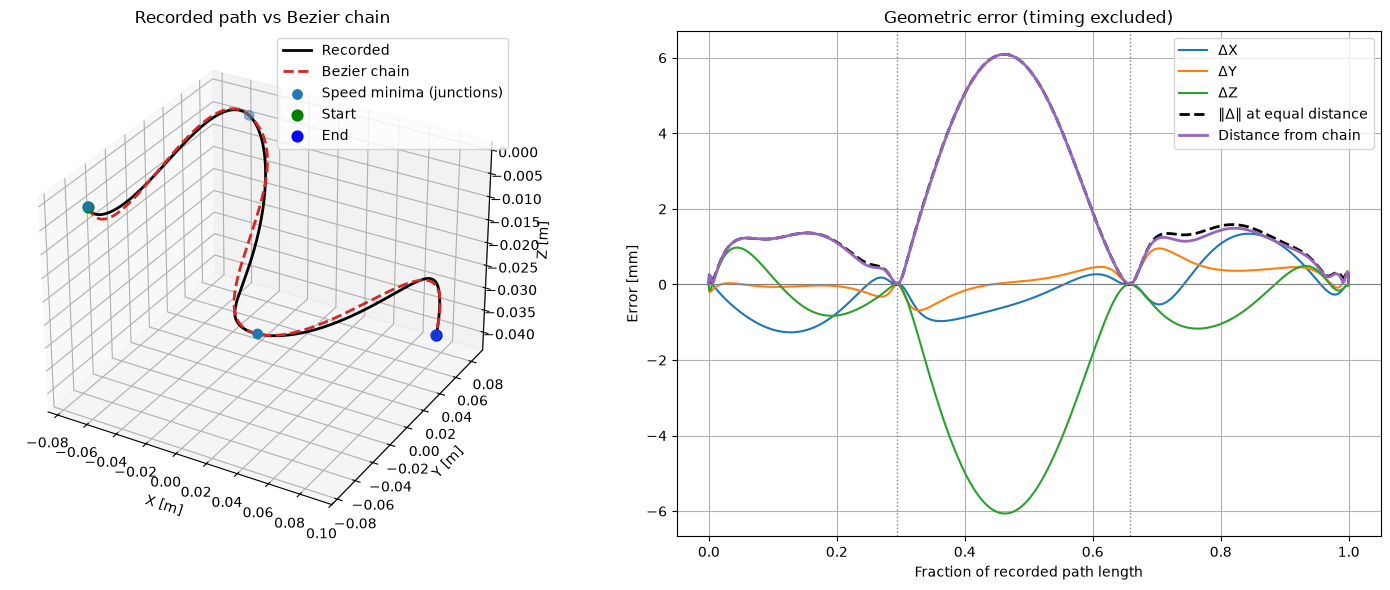

Recorded path length: 533.38 mm, Bezier chain length: 533.38 mm
Shape SNR: 32.44 dB
Error at equal distance: mean 1.402 mm, max 6.092 mm
Distance from chain:     mean 1.372 mm, max 6.092 mm
          D [mm]  Bezier length [mm]  Recorded length [mm]  lambda_s [mm]  lambda_e [mm]  Fit RMSE [mm]
Segment                                                                                                
1        157.229             157.229               157.229         39.558         32.408          0.853
2        193.773             193.773               193.773         41.151         46.260          3.662
3        182.381             182.381               182.381         48.777         38.130          0.964


In [22]:
from scipy.spatial import cKDTree

# Recorded samples covered by the Bezier chain, from the first to the last kept speed minimum
first_idx, last_idx = int(minima_idx_strokes[0]), int(minima_idx_strokes[-1])
junction_local_idx = np.asarray(minima_idx_strokes, dtype=int) - first_idx
recorded_points = np.asarray(recording.curve.points)[first_idx:last_idx + 1]
recorded_time = np.asarray(recording.t)[first_idx:last_idx + 1]
filtered_curve = Curve(x=recorded_points[:, 0], y=recorded_points[:, 1], z=recorded_points[:, 2], t=recorded_time)

# Distance travelled along the recorded path from the first kept speed minimum
recorded_travelled = np.concatenate([[0.0], np.cumsum(np.linalg.norm(np.diff(recorded_points, axis=0), axis=1))])
recorded_fraction = recorded_travelled / recorded_travelled[-1]
junction_fraction = recorded_fraction[junction_local_idx[1:-1]]

# Shape error: chain point at the same travelled distance as each recorded sample (timing excluded)
chain_aligned = sample_chain_by_distance(curve_params, segment_start_points, recorded_travelled)
shape_difference = recorded_points - chain_aligned
shape_error = np.linalg.norm(shape_difference, axis=1)
chain_aligned_curve = Curve(x=chain_aligned[:, 0], y=chain_aligned[:, 1], z=chain_aligned[:, 2], t=recorded_time)

# Path error: distance of each recorded sample from the closest point of the chain
chain_dense = sample_chain_by_distance(curve_params, segment_start_points, np.linspace(0.0, chain_length, 5000))
path_error, _ = cKDTree(chain_dense).query(recorded_points)

fig = plt.figure(figsize=(15, 6))

# 3D comparison between the recorded path and the Bezier chain
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.plot(*recorded_points.T, color="black", linewidth=2, label="Recorded")
ax1.plot(*chain_dense.T, color="tab:red", linestyle="--", linewidth=2, label="Bezier chain")
ax1.scatter(*recorded_points[junction_local_idx].T, color="tab:blue", s=45, label="Speed minima (junctions)", zorder=4)
ax1.scatter(*recorded_points[0], color="green", s=60, label="Start")
ax1.scatter(*recorded_points[-1], color="blue", s=60, label="End")
ax1.set_xlabel("X [m]")
ax1.set_ylabel("Y [m]")
ax1.set_zlabel("Z [m]")
ax1.set_title("Recorded path vs Bezier chain")
ax1.legend()

# Shape and path errors along the recorded path
ax2 = fig.add_subplot(1, 2, 2)
for axis, label in enumerate(["ΔX", "ΔY", "ΔZ"]):
  ax2.plot(recorded_fraction, shape_difference[:, axis] * 1e3, label=label)
ax2.plot(recorded_fraction, shape_error * 1e3, "k--", linewidth=2, label="‖Δ‖ at equal distance")
ax2.plot(recorded_fraction, path_error * 1e3, color="tab:purple", linewidth=2, label="Distance from chain")
for fraction in junction_fraction:
  ax2.axvline(fraction, color="gray", linestyle=":", linewidth=1)
ax2.axhline(0, color="gray", linewidth=0.8)
ax2.set_xlabel("Fraction of recorded path length")
ax2.set_ylabel("Error [mm]")
ax2.set_title("Geometric error (timing excluded)")
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()

print(f"Recorded path length: {recorded_travelled[-1] * 1e3:.2f} mm, Bezier chain length: {chain_length * 1e3:.2f} mm")
print(f"Shape SNR: {filtered_curve.snr(chain_aligned_curve):.2f} dB")
print(f"Error at equal distance: mean {shape_error.mean() * 1e3:.3f} mm, max {shape_error.max() * 1e3:.3f} mm")
print(f"Distance from chain:     mean {path_error.mean() * 1e3:.3f} mm, max {path_error.max() * 1e3:.3f} mm")

# Per-segment summary: shared D, fitted geometry and recorded length of the same window
segment_table = pd.DataFrame({
  "D [mm]": np.asarray(Ds) * 1e3,
  "Bezier length [mm]": [seg["length"] * 1e3 for seg in curve_params],
  "Recorded length [mm]": np.diff(recorded_travelled[junction_local_idx]) * 1e3,
  "lambda_s [mm]": [seg["lambda_s"] * 1e3 for seg in curve_params],
  "lambda_e [mm]": [seg["lambda_e"] * 1e3 for seg in curve_params],
  "Fit RMSE [mm]": [np.sqrt(seg["error"]) * 1e3 for seg in curve_params],
}, index=pd.Index(range(1, len(curve_params) + 1), name="Segment"))
print(segment_table.round(3).to_string())


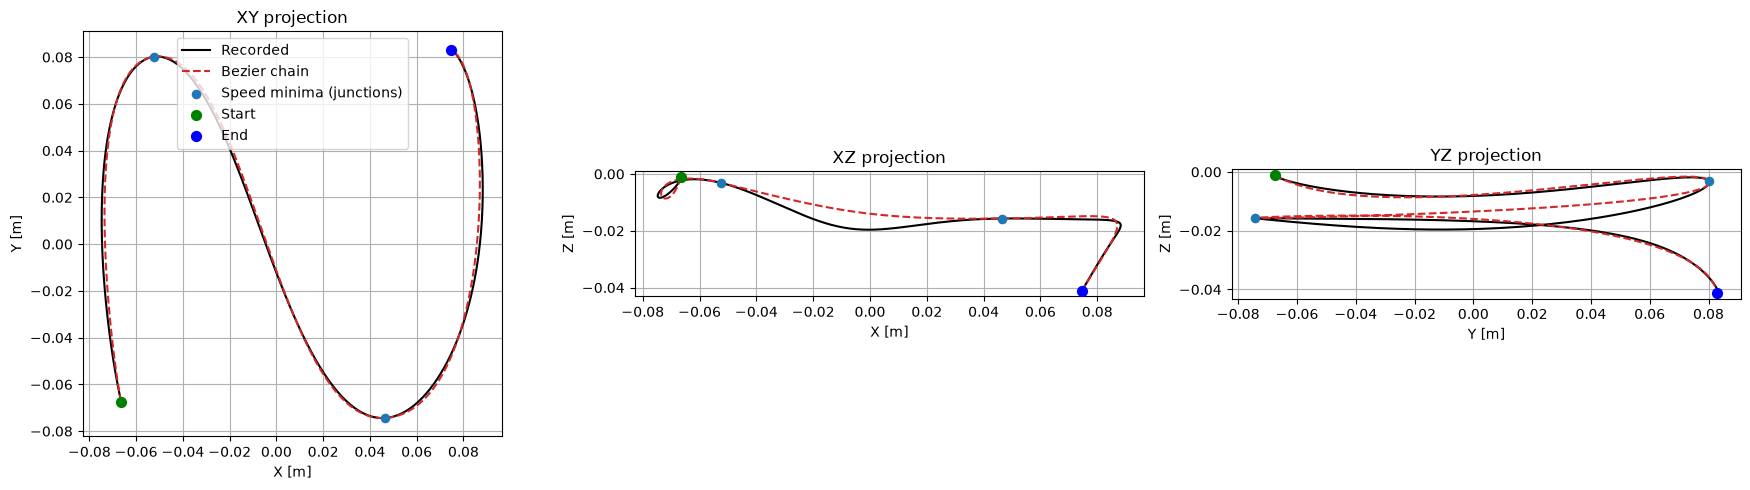

In [23]:
# Recorded path and Bezier chain in the three coordinate planes
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

projections = [
  (0, 1, "X", "Y", "XY"),
  (0, 2, "X", "Z", "XZ"),
  (1, 2, "Y", "Z", "YZ"),
]

for ax, (i, j, xlabel, ylabel, title) in zip(axes, projections):
  ax.plot(recorded_points[:, i], recorded_points[:, j], color="black", linewidth=1.5, label="Recorded")
  ax.plot(chain_dense[:, i], chain_dense[:, j], color="tab:red", linestyle="--", linewidth=1.5, label="Bezier chain")
  ax.scatter(recorded_points[junction_local_idx, i], recorded_points[junction_local_idx, j],
             color="tab:blue", s=35, label="Speed minima (junctions)", zorder=3)
  ax.scatter(recorded_points[0, i], recorded_points[0, j], color="green", s=50, label="Start", zorder=3)
  ax.scatter(recorded_points[-1, i], recorded_points[-1, j], color="blue", s=50, label="End", zorder=3)
  ax.set_xlabel(f"{xlabel} [m]")
  ax.set_ylabel(f"{ylabel} [m]")
  ax.set_title(f"{title} projection")
  ax.set_aspect("equal", adjustable="box")
  ax.grid(True)

axes[0].legend()

plt.tight_layout()
plt.show()


### Timing: generated movement vs recording

Speed, velocity components, along-path shift and position error on the absolute time axis. Gray dotted lines are the recorded speed minima, red dotted lines the times at which the generated movement crosses the junctions.

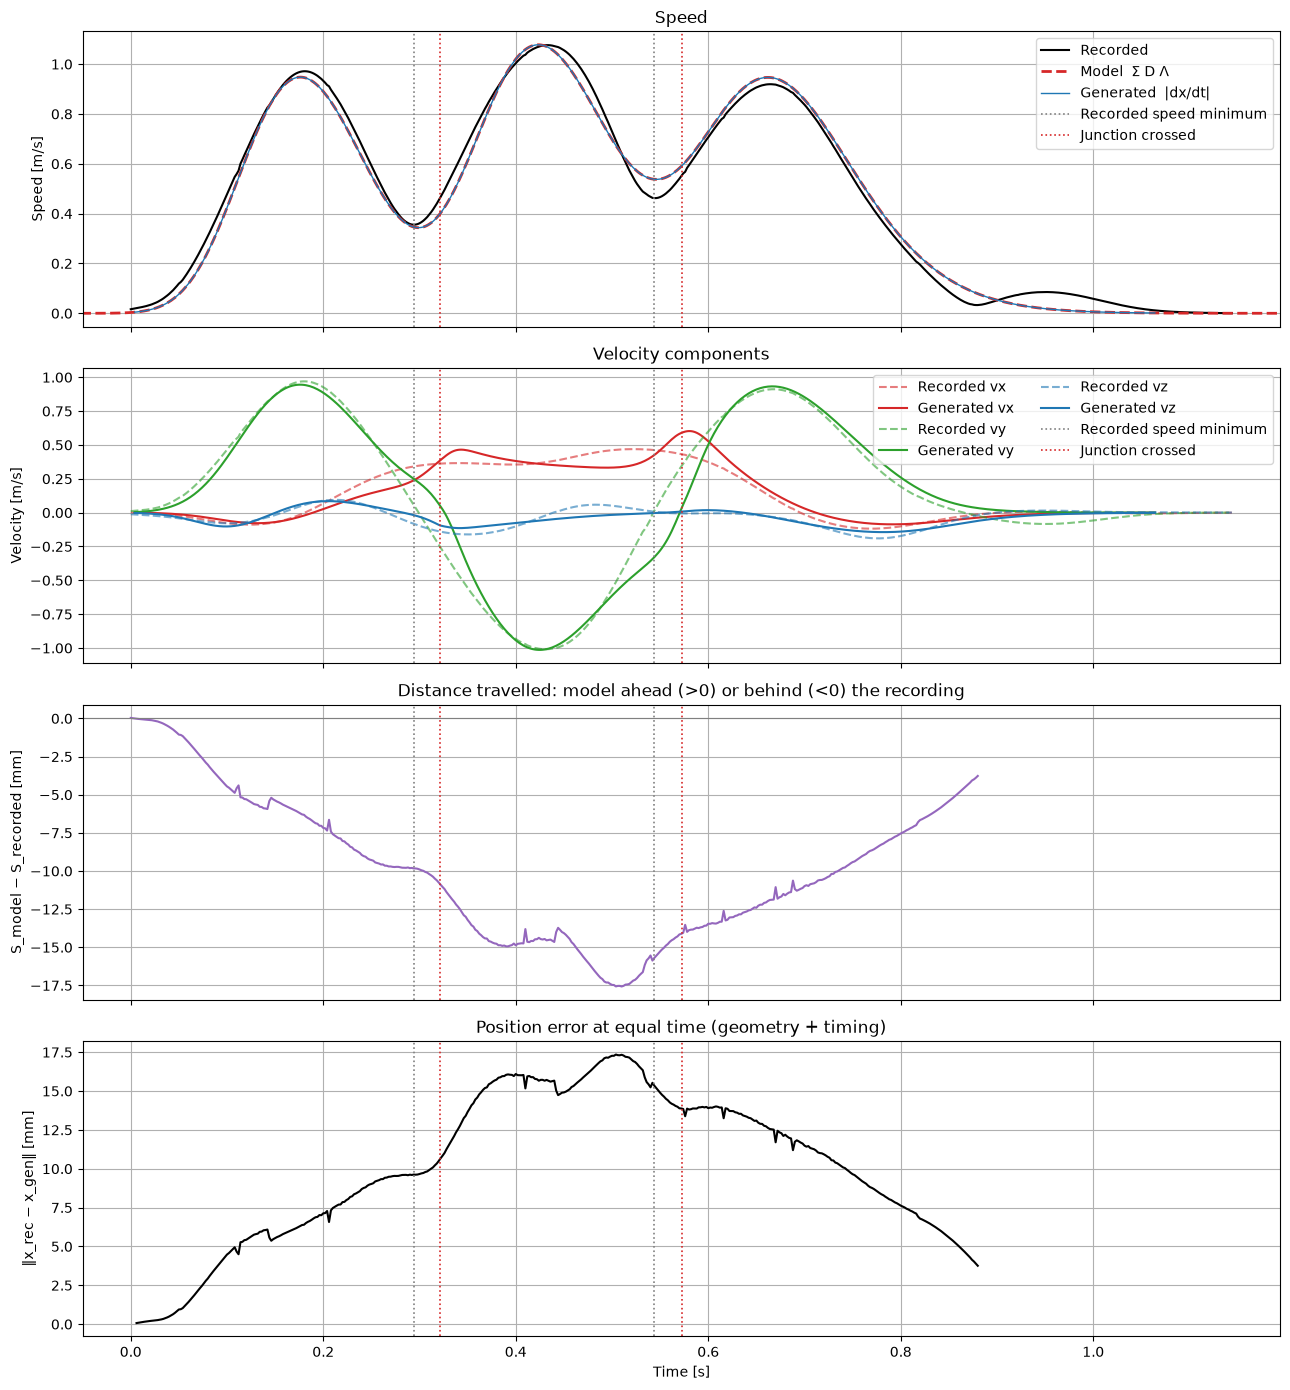

Speed SNR, model vs recorded:     23.52 dB
Speed SNR, generated vs recorded: 23.51 dB
Max |generated − model| speed: 0.277 mm/s
Largest speed change between samples: generated 20.258 mm/s, model 20.266 mm/s
Along-path shift: mean |·| 9.75 mm, max |·| 17.57 mm
Position error at equal time: mean 10.02 mm, max 17.35 mm


In [24]:
# Speed and velocity of the generated movement
generated_velocity = np.gradient(generated_points, t_generated, axis=0)
generated_speed = np.linalg.norm(generated_velocity, axis=1)

# Recorded speed and velocity on the whole recording
recorded_t_full = np.asarray(recording.trajectory.t)
recorded_speed_full = np.asarray(recording.trajectory.speed)
recorded_velocity_full = np.column_stack([recording.trajectory.vx, recording.trajectory.vy, recording.trajectory.vz])

# Generated and model speed on the recorded time base (zero where the generated movement is at rest)
generated_speed_on_recording = np.interp(recorded_t_full, t_generated, generated_speed, left=0.0, right=0.0)
model_speed_on_recording = np.interp(recorded_t_full, t_model, speed_model)

# Along-path shift between model and recording: positive when the model is ahead
travelled_model_at_recorded = np.interp(recorded_time, t_model, travelled_model)
path_shift = travelled_model_at_recorded - recorded_travelled

# Position error at equal time, where the generated movement is defined
overlap = (recorded_time >= t_generated[0]) & (recorded_time <= t_generated[-1])
generated_at_recorded = np.column_stack([
  np.interp(recorded_time[overlap], t_generated, generated_points[:, axis]) for axis in range(3)
])
position_error = np.linalg.norm(recorded_points[overlap] - generated_at_recorded, axis=1)

fig, axes = plt.subplots(4, 1, figsize=(13, 14), sharex=True)


def mark_junctions(ax):
  """Recorded speed minima (gray) and junction crossing times of the generated movement (red)."""
  for k, t_min in enumerate(minima_times):
    ax.axvline(t_min, color="gray", linestyle=":", linewidth=1.2, label="Recorded speed minimum" if k == 0 else None)
  for k, tau in enumerate(junction_times):
    ax.axvline(tau, color="tab:red", linestyle=":", linewidth=1.2, label="Junction crossed" if k == 0 else None)


# Speed profiles
axes[0].plot(recorded_t_full, recorded_speed_full, color="black", linewidth=1.5, label="Recorded")
axes[0].plot(t_model, speed_model, color="tab:red", linestyle="--", linewidth=2, label="Model  Σ D Λ")
axes[0].plot(t_generated, generated_speed, color="tab:blue", linewidth=1, label="Generated  |dx/dt|")
mark_junctions(axes[0])
axes[0].set_ylabel("Speed [m/s]")
axes[0].set_title("Speed")
axes[0].grid(True)
axes[0].legend(loc="upper right")

# Velocity components: continuity of the direction across junctions
for axis, (label, color) in enumerate(zip(["X", "Y", "Z"], ["tab:red", "tab:green", "tab:blue"])):
  axes[1].plot(recorded_t_full, recorded_velocity_full[:, axis], color=color, linestyle="--", alpha=0.6, label=f"Recorded v{label.lower()}")
  axes[1].plot(t_generated, generated_velocity[:, axis], color=color, linewidth=1.5, label=f"Generated v{label.lower()}")
mark_junctions(axes[1])
axes[1].set_ylabel("Velocity [m/s]")
axes[1].set_title("Velocity components")
axes[1].grid(True)
axes[1].legend(loc="upper right", ncol=2)

# Along-path shift
axes[2].plot(recorded_time, path_shift * 1e3, color="tab:purple", linewidth=1.5)
axes[2].axhline(0, color="gray", linewidth=0.8)
mark_junctions(axes[2])
axes[2].set_ylabel("S_model − S_recorded [mm]")
axes[2].set_title("Distance travelled: model ahead (>0) or behind (<0) the recording")
axes[2].grid(True)

# Position error at equal time
axes[3].plot(recorded_time[overlap], position_error * 1e3, color="black", linewidth=1.5)
mark_junctions(axes[3])
axes[3].set_xlabel("Time [s]")
axes[3].set_ylabel("‖x_rec − x_gen‖ [mm]")
axes[3].set_title("Position error at equal time (geometry + timing)")
axes[3].grid(True)

# Time window covering the recording and the generated movement
axes[3].set_xlim(min(recorded_t_full[0], t_generated[0]) - 0.05, max(recorded_t_full[-1], t_generated[-1]) + 0.05)

plt.tight_layout()
plt.show()

# Edge samples excluded: np.gradient is one-sided there
inner = slice(2, -2)
print(f"Speed SNR, model vs recorded:     {SNR(recorded_speed_full, model_speed_on_recording):.2f} dB")
print(f"Speed SNR, generated vs recorded: {SNR(recorded_speed_full, generated_speed_on_recording):.2f} dB")
print(f"Max |generated − model| speed: {np.abs(generated_speed - speed_model_generated)[inner].max() * 1e3:.3f} mm/s")
print(f"Largest speed change between samples: generated {np.abs(np.diff(generated_speed[inner])).max() * 1e3:.3f} mm/s, "
      f"model {np.abs(np.diff(speed_model_generated[inner])).max() * 1e3:.3f} mm/s")
print(f"Along-path shift: mean |·| {np.abs(path_shift).mean() * 1e3:.2f} mm, max |·| {np.abs(path_shift).max() * 1e3:.2f} mm")
print(f"Position error at equal time: mean {position_error.mean() * 1e3:.2f} mm, max {position_error.max() * 1e3:.2f} mm")


Time 1 mm from start: 0.038000 s
Time 1 mm from end: 0.858000 s


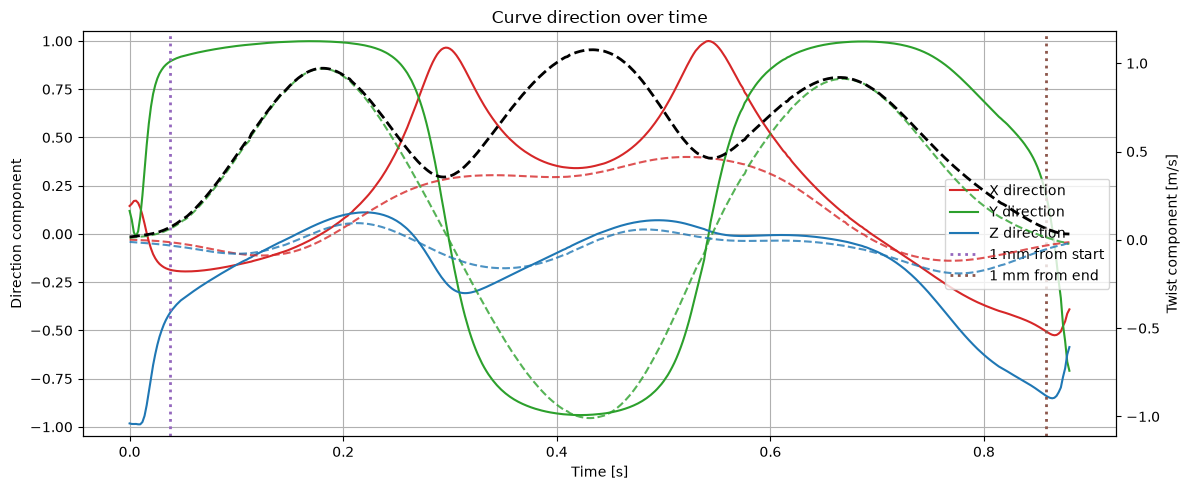

In [25]:
# Compute the normalized tangent direction of the recorded curve.
recorded_points = np.asarray(filtered_curve.points)
recorded_time = np.asarray(filtered_curve.t)
curve_velocity = np.gradient(recorded_points, recorded_time, axis=0)
curve_speed = np.linalg.norm(curve_velocity, axis=1)

direction = np.divide(
  curve_velocity,
  curve_speed[:, None],
  out=np.zeros_like(curve_velocity),
  where=curve_speed[:, None] > 1e-12,
)

fig, ax = plt.subplots(figsize=(12, 5))

for axis, label, color in zip(range(3), ["X", "Y", "Z"], ["tab:red", "tab:green", "tab:blue"]):
  ax.plot(
    recorded_time,
    direction[:, axis],
    label=f"{label} direction",
    color=color,
  )

ax.set_xlabel("Time [s]")
ax.set_ylabel("Direction component")
ax.set_title("Curve direction over time")
ax.set_ylim(-1.05, 1.05)
ax.grid(True)
ax.legend()

twist_time = np.asarray(recording.trajectory.t)
twist_components = np.column_stack([
  recording.trajectory.vx,
  recording.trajectory.vy,
  recording.trajectory.vz,
])

twist_interpolated = np.column_stack([
  np.interp(recorded_time, twist_time, twist_components[:, axis])
  for axis in range(3)
])

ax_twist = ax.twinx()

for axis, label, color in zip(
  range(3),
  ["X", "Y", "Z"],
  ["tab:red", "tab:green", "tab:blue"],
):
  ax_twist.plot(
    recorded_time,
    twist_interpolated[:, axis],
    linestyle="--",
    color=color,
    alpha=0.8,
    label=f"Twist {label}",
  )

ax_twist.set_ylabel("Twist component [m/s]")

handles, labels = ax.get_legend_handles_labels()
twist_handles, twist_labels = ax_twist.get_legend_handles_labels()
ax.legend(handles + twist_handles, labels + twist_labels, loc="best")

twist_speed = np.linalg.norm(twist_interpolated, axis=1)

ax_twist.plot(
  recorded_time,
  twist_speed,
  "k--",
  linewidth=2,
  label="Speed magnitude",
)

handles, labels = ax.get_legend_handles_labels()
twist_handles, twist_labels = ax_twist.get_legend_handles_labels()
ax.legend(handles + twist_handles, labels + twist_labels, loc="best")

# Compute cumulative distance along the recorded curve.
segment_lengths = np.linalg.norm(np.diff(recorded_points, axis=0), axis=1)
cumulative_distance = np.r_[0.0, np.cumsum(segment_lengths)]
total_length = cumulative_distance[-1]

distance_to_plot = 0.001  # 1/2 mm

if total_length < 2 * distance_to_plot:
  raise ValueError("The curve is shorter than 2 mm.")

start_idx = np.searchsorted(cumulative_distance, distance_to_plot)
end_idx = np.searchsorted(
  cumulative_distance,
  total_length - distance_to_plot,
)

start_time_1mm = recorded_time[start_idx]
end_time_1mm = recorded_time[end_idx]

ax.axvline(
  start_time_1mm,
  color="tab:purple",
  linestyle=":",
  linewidth=2,
  label="1 mm from start",
)
ax.axvline(
  end_time_1mm,
  color="tab:brown",
  linestyle=":",
  linewidth=2,
  label="1 mm from end",
)

ax.legend(loc="best")

print(f"Time 1 mm from start: {start_time_1mm:.6f} s")
print(f"Time 1 mm from end: {end_time_1mm:.6f} s")

plt.tight_layout()
plt.show()